# CU-BEMS Intelligence Suite — Question 1 (Operational Baseload)
## Notebook 1D: Schedule Merging & Temporal Segmentation (`qn1d_schedule_merge.ipynb`)

---

### Purpose & Context Unification
This notebook merges the cleaned telemetry from `qn1c_data_cleaning.ipynb` with the external Bank of Thailand holidays and Chulalongkorn academic calendar from `qn1a_external_data_import.ipynb`.

### Operational Regime Rules:
1. **Occupied Regime**:
   * Monday through Friday, **08:00 to 17:00**.
   * Excludes official public holidays and statutory campus closures.

2. **Unoccupied Regime (Target Scope for Question 1 Baseload Waste)**:
   * **Weekday Evenings / Nights**: 17:00 to 08:00 next morning.
   * **All Weekends**: Saturday (00:00 to 24:00) and Sunday (00:00 to 24:00).
   * **All Public Holidays (47 Days)**: 24 hours per day.

3. **Train / Test Temporal Partition (Zero Data Leakage)**:
   * **Training Window (First 12 Months)**: July 1, 2018 – June 30, 2019 (365 days).
   * **Testing / Holdout Window (Final 6 Months)**: July 1, 2019 – December 31, 2019 (184 days).

**Final Clean Deliverable:** Generates the master clean dataset in `../data/qn1_clean_master_merged.csv` and `../data/clean_merged_Floor{1-7}.csv`.


In [1]:
# ==============================================================================
# 1. ENVIRONMENT & DATA DIRECTORY INITIALIZATION
# ==============================================================================
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

notebook_dir = os.getcwd()
data_dir = os.path.abspath(os.path.join(notebook_dir, "..", "data"))
print(f"[OK] Merging engine ready.\n  Data Cache: {data_dir}")

[OK] Merging engine ready.
  Data Cache: C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data


## 2. Ingesting External Bank of Thailand Public Holidays
We load the public holidays table generated in `qn1a_external_data_import.ipynb`.

In [2]:
# ==============================================================================
# 2. LOAD THAI PUBLIC HOLIDAYS
# ==============================================================================
holidays_path = os.path.join(data_dir, "thai_holidays_18months.csv")
if os.path.exists(holidays_path):
    holidays_df = pd.read_csv(holidays_path)
    holiday_dates = set(pd.to_datetime(holidays_df['Date']).dt.date)
    print(f"[OK] Loaded {len(holiday_dates)} Bank of Thailand public holiday dates from: {holidays_path}")
else:
    import holidays
    th_holidays = holidays.Thailand(years=[2018, 2019])
    holiday_dates = set(pd.to_datetime(list(th_holidays.keys())).date)
    print(f"[FALLBACK] Loaded {len(holiday_dates)} holiday dates via python-holidays package.")

[OK] Loaded 36 Bank of Thailand public holiday dates from: C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\thai_holidays_18months.csv


## 3. Floor-by-Floor Operational Regime & Split Integration
We process each cleaned floor dataset, tagging calendar features, occupancy status, and the 12-month / 6-month partition.

In [3]:
# ==============================================================================
# 3. MERGE OPERATIONAL REGIMES ACROSS ALL 7 FLOORS
# ==============================================================================
TRAIN_CUTOFF = pd.Timestamp('2019-06-30 23:59:59')
merged_floors = {}
regime_summary = []

for floor_num in range(1, 8):
    floor_key = f"Floor{floor_num}"
    clean_file = os.path.join(data_dir, f"clean_{floor_key}.csv")
    
    if not os.path.exists(clean_file):
        print(f"[ERROR] Clean file not found: {clean_file}. Run qn1c_data_cleaning.ipynb first.")
        continue
        
    df = pd.read_csv(clean_file, parse_dates=['Date'], index_col='Date')
    
    # Temporal feature engineering
    df['DayOfWeek'] = df.index.dayofweek # 0=Mon, 4=Fri, 5=Sat, 6=Sun
    df['Hour'] = df.index.hour
    df['Date_Only'] = df.index.date
    
    df['Is_Holiday'] = df['Date_Only'].isin(holiday_dates)
    df['Is_Weekend'] = df['DayOfWeek'] >= 5
    
    # Operational regime classification
    df['Is_Occupied'] = (
        (~df['Is_Weekend']) & 
        (~df['Is_Holiday']) & 
        (df['Hour'] >= 8) & 
        (df['Hour'] < 17)
    )
    df['Is_Unoccupied'] = ~df['Is_Occupied']
    
    # 12-month Train / 6-month Test partition
    df['Split'] = np.where(df.index <= TRAIN_CUTOFF, 'Train', 'Test')
    
    merged_floors[floor_key] = df
    
    occ_hrs = df['Is_Occupied'].sum() / 60.0
    unocc_hrs = df['Is_Unoccupied'].sum() / 60.0
    total_hrs = len(df) / 60.0
    
    regime_summary.append({
        'Floor': floor_key,
        'Total_Hours': round(total_hrs, 1),
        'Occupied_Hours': round(occ_hrs, 1),
        'Occupied_%': round(occ_hrs / total_hrs * 100, 1),
        'Unoccupied_Hours': round(unocc_hrs, 1),
        'Unoccupied_%': round(unocc_hrs / total_hrs * 100, 1),
        'Train_Records': (df['Split'] == 'Train').sum(),
        'Test_Records': (df['Split'] == 'Test').sum()
    })

regime_df = pd.DataFrame(regime_summary)
print("[SUCCESS] Calendar regimes and train/test splits successfully merged.")
display(regime_df)


[SUCCESS] Calendar regimes and train/test splits successfully merged.


,Floor,Total_Hours,Occupied_Hours,Occupied_%,Unoccupied_Hours,Unoccupied_%,Train_Records,Test_Records
0,Floor1,13176.0,3294.0,25.0,9882.0,75.0,525600,264960
1,Floor2,13176.0,3294.0,25.0,9882.0,75.0,525600,264960
2,Floor3,13176.0,3294.0,25.0,9882.0,75.0,525600,264960
3,Floor4,13176.0,3294.0,25.0,9882.0,75.0,525600,264960
4,Floor5,13176.0,3294.0,25.0,9882.0,75.0,525600,264960
5,Floor6,11485.5,2876.5,25.0,8609.0,75.0,525600,163528
6,Floor7,13176.0,3294.0,25.0,9882.0,75.0,525600,264960


## 4. Regime Distribution Visualization
The building spends **75.0% (with 25.0% Occupied) of its operating timeline in the Unoccupied state**, proving the high financial return of automated after-hours curfew sweeps.

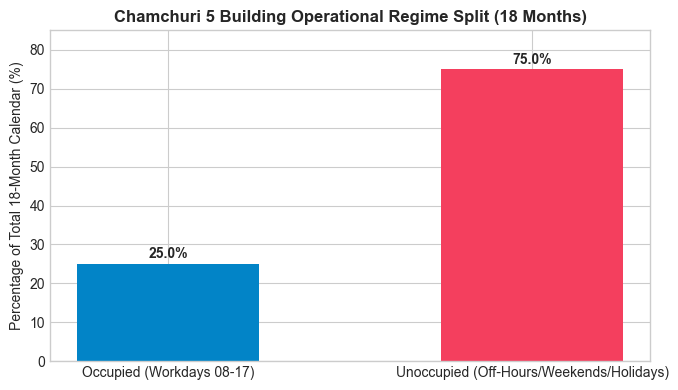

In [4]:
# ==============================================================================
# 4. VISUALIZE OPERATIONAL REGIME SPLIT
# ==============================================================================
sample_floor = merged_floors['Floor1']
occ_pct = sample_floor['Is_Occupied'].mean() * 100
unocc_pct = sample_floor['Is_Unoccupied'].mean() * 100

plt.figure(figsize=(7, 4))
bars = plt.bar(['Occupied (Workdays 08-17)', 'Unoccupied (Off-Hours/Weekends/Holidays)'], 
               [occ_pct, unocc_pct], color=['#0284C7', '#F43F5E'], width=0.5)
plt.ylabel('Percentage of Total 18-Month Calendar (%)')
plt.title('Chamchuri 5 Building Operational Regime Split (18 Months)', fontweight='bold')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1.5, f"{yval:.1f}%", ha='center', fontweight='bold')
plt.ylim(0, 85)
plt.tight_layout()
plt.show()


## 5. Persisting Final Cleaned Merged Datasets
We save individual floor files `../data/clean_merged_Floor{1-7}.csv` as well as a consolidated master table.

In [5]:
# ==============================================================================
# 5. PERSIST FINAL CLEAN MERGED DATASETS & CONSOLIDATED HOURLY MASTER
# ==============================================================================
for floor_key, df in merged_floors.items():
    m_path = os.path.join(data_dir, f"clean_merged_{floor_key}.csv")
    df.to_csv(m_path)
    print(f"[SAVED] {floor_key} clean merged table -> {m_path}")

# Construct consolidated building hourly master table for Excel & cross-floor modeling
print("\n[EXPORT] Generating consolidated hourly master table...")
hourly_frames = []
for floor_key, df in merged_floors.items():
    elec_cols = [c for c in df.columns if ('_Light(kW)' in c) or ('_Plug(kW)' in c)]
    df_h = df[elec_cols].resample('1h').mean()
    df_h.columns = [f"{floor_key}_{c}" for c in df_h.columns]
    hourly_frames.append(df_h)

master_hourly = pd.concat(hourly_frames, axis=1)

# Attach calendar regime flags from reference floor (Floor 1 has full temporal grid)
f1 = merged_floors['Floor1']
f1_h = f1[['Is_Occupied', 'Is_Unoccupied']].resample('1h').max()
f1_h['Is_Train_Period'] = (f1['Split'] == 'Train').resample('1h').max().astype(int)
master_hourly = pd.concat([f1_h, master_hourly], axis=1)
master_hourly.index.name = 'Date'

master_path = os.path.join(data_dir, "qn1_hourly_master_for_excel.csv")
master_hourly.to_csv(master_path)
print(f"[SAVED] Consolidated hourly master table -> {master_path} ({len(master_hourly):,} hours, {master_hourly.shape[1]} columns)")

print("\n[SUMMARY] Data pipeline complete! All cleaned datasets are saved in ../data/.")
print("Proceed to 'qn1e_eda_and_baseload_modeling.ipynb' for EDA, Baseload Derivation, and Financial Recovery!")


[SAVED] Floor1 clean merged table -> C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\clean_merged_Floor1.csv


[SAVED] Floor2 clean merged table -> C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\clean_merged_Floor2.csv


[SAVED] Floor3 clean merged table -> C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\clean_merged_Floor3.csv


[SAVED] Floor4 clean merged table -> C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\clean_merged_Floor4.csv


[SAVED] Floor5 clean merged table -> C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\clean_merged_Floor5.csv


[SAVED] Floor6 clean merged table -> C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\clean_merged_Floor6.csv


[SAVED] Floor7 clean merged table -> C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\clean_merged_Floor7.csv

[EXPORT] Generating consolidated hourly master table...


[SAVED] Consolidated hourly master table -> C:\Users\65964\OneDrive\Desktop\IS4001\proj\qn1\data\qn1_hourly_master_for_excel.csv (13,176 hours, 68 columns)

[SUMMARY] Data pipeline complete! All cleaned datasets are saved in ../data/.
Proceed to 'qn1e_eda_and_baseload_modeling.ipynb' for EDA, Baseload Derivation, and Financial Recovery!
